In [1]:
import jax
import jax.numpy as jnp

import matplotlib.pyplot as plt

from agfx.gym import create_state, from_amat
from agfx.special.linear_gaussian import sample_linear_gaussian
from agfx.rewards import create_log_reward, LogRewardType 
from agfx.training import LossType, train_step, create_opt
from agfx.policies import GFlowNet

import time

In [2]:
bs = 64
dmid = 64

logr_t = LogRewardType.BIC
loss_t = LossType.TB

seed = 42

reward_seed = 43

In [ ]:
def evaluate(num_nodes: int, iterations: int = 20):
    reward_key = jax.random.key(reward_seed)
    data, dir_amat, bidir_amat, *_ = sample_linear_gaussian(
        reward_key, num_nodes, num_samples=100
    )
    true_graph = from_amat((dir_amat + bidir_amat)[None])
    key = jax.random.key(seed)
    state = create_state(bs, num_nodes)
    gfn = GFlowNet(num_nodes, dmid, seed=seed)
    logr = create_log_reward(logr_t, data, true_graph)
    opt = create_opt(gfn, iterations=iterations)

    train_step_compiled = train_step.lower(
        gfn, state, key, logr, opt, loss_t
    ).compile()

    # Warm-up: one un-timed iteration to flush any residual dispatch overhead
    loss, key = train_step_compiled(gfn, state, key, opt)
    jax.block_until_ready((loss, key))

    elapsed = 0.0
    for _ in range(iterations):
        s = time.perf_counter()
        loss, key = train_step_compiled(gfn, state, key, opt)
        jax.block_until_ready((loss, key))
        elapsed += time.perf_counter() - s

    return elapsed / iterations

In [41]:
num_nodes_arr = jnp.array(range(2, 51))

In [42]:
elapsed = [] 

for num_nodes in num_nodes_arr:
    elapsed.append(evaluate(num_nodes=num_nodes))

KeyboardInterrupt: 

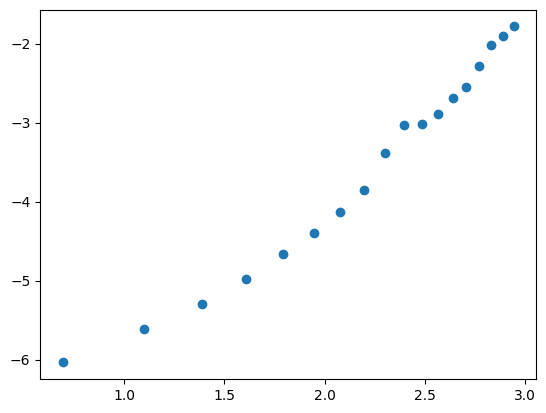

In [115]:
plt.scatter(log_x, log_y)

In [125]:
from mpl_preamble import *

Estimated exponent: 2.708
R² (log-log):       0.9880


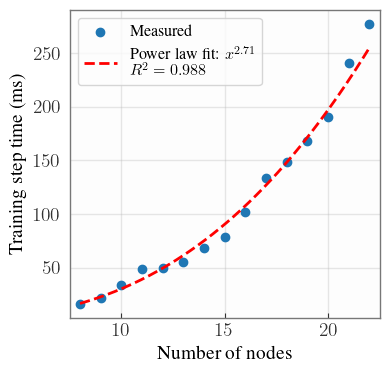

In [139]:
import numpy as np
from scipy import stats

plt.figure(figsize=(4, 4))

idx = 21 

x = num_nodes_arr[6:idx]
y = elapsed[6:idx]

# Fit in log-log space: log(y) = n*log(x) + log(c)
log_x = np.log(x)
log_y = np.log(y)
slope, intercept, r_value, p_value, se = stats.linregress(log_x, log_y)

print(f"Estimated exponent: {slope:.3f}")
print(f"R² (log-log):       {r_value**2:.4f}")

# Plot original data + fitted power law
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = np.exp(intercept) * x_fit**slope

plt.scatter(x, [d * 1e3 for d in y], label="Measured")
plt.plot(x_fit, y_fit * 1e3, 'r--', label=f"Power law fit: $x^{{{slope:.2f}}}$\n$R^{{2}} = 0.988$")
plt.xlabel("Number of nodes")
plt.ylabel("Training step time (ms)")
plt.legend()

plt.xlim(x.min() - .5, x.max() + .5)

plt.savefig("figures/train_steps.pdf", bbox_inches="tight")

plt.show()